# BC03 — Partie 2 | Choix de modèles et hyperparamètres

Prédire `retour` **au moment de la vente** (0/1). Utilisez 2025 pour entraînement + validation et 2026 **une seule fois** pour le test final. Les cellules de solution sont à compléter.

## Étape 0 — Chargement

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np

def trouver_donnees():
    bases = [Path.cwd(), Path.cwd().parent, Path('/content'), Path('/content/CycleNova_Entrainement_RNCP38616')]
    for base in bases:
        for d in (base / 'DONNEES', base / 'CycleNova_Entrainement_RNCP38616' / 'DONNEES'):
            if (d / 'ventes.csv').is_file() and (d / 'produits.csv').is_file() and (d / 'prix_concurrents.csv').is_file():
                return d
    archive = Path('/content/CycleNova_Entrainement_RNCP38616.zip')
    if archive.exists():
        import zipfile
        with zipfile.ZipFile(archive) as z:
            z.extractall('/content')
        return trouver_donnees()
    raise FileNotFoundError('Dossier DONNEES absent. Consultez LISEZMOI.md et conservez la structure des dossiers.')

DATA = trouver_donnees()
produits = pd.read_csv(DATA / 'produits.csv')
ventes = pd.read_csv(DATA / 'ventes.csv')
prix_concurrents = pd.read_csv(DATA / 'prix_concurrents.csv')
print(f'Données chargées : produits={len(produits)}, ventes={len(ventes)}, prix_concurrents={len(prix_concurrents)}')

Données chargées : produits=65, ventes=3005, prix_concurrents=2818


## Étape 1 — Cible, granularité et fuite d’information

1. `retour` est-il connu au moment de la vente ? Expliquez l’usage d’une étiquette historique.
2. Pourquoi `date_retour` et `motif_retour` sont-ils interdits comme prédicteurs au moment de la commande ?
3. Pourquoi les relevés de prix concurrents ultérieurs à la vente sont-ils dangereux pour la prédiction ?
4. Analysez les clés manquantes, les retours invalides et les doublons. Justifiez l’échantillon conservé.

In [2]:
# Contrôle qualité des ventes (étape 1, point 4)
print("Lignes au départ :", len(ventes))
print("Doublons d'id_vente :", ventes["id_vente"].duplicated().sum())
print("id_produit manquant :", ventes["id_produit"].isna().sum())

# Produits : on garde une seule ligne par id_produit (il y a un doublon)
produits_propres = produits.drop_duplicates(subset="id_produit")
print("id_produit inconnu (absent de produits) :",
      (ventes["id_produit"].notna() & ~ventes["id_produit"].isin(produits_propres["id_produit"])).sum())

print("Valeurs de retour :")
print(ventes["retour"].value_counts(dropna=False))
print("quantité <= 0 :", (ventes["quantite"] <= 0).sum())
print("prix <= 0 ou manquant :", ((ventes["prix_unitaire"] <= 0) | ventes["prix_unitaire"].isna()).sum())
print("remise hors [0,1] :", ((ventes["taux_remise"] < 0) | (ventes["taux_remise"] > 1)).sum())
print("canal manquant :", ventes["canal"].isna().sum())

# Nettoyage : on enlève les lignes invalides
v = ventes.drop_duplicates(subset="id_vente").copy()           # doublons
v = v[v["id_produit"].isin(produits_propres["id_produit"])]      # clé manquante ou inconnue
v = v[v["retour"].isin([0, 1])]                                  # retour invalide ou manquant
v = v[(v["quantite"] > 0) & (v["prix_unitaire"] > 0)]            # quantité et prix valides
v = v[(v["taux_remise"] >= 0) & (v["taux_remise"] <= 1)]         # remise entre 0 et 1
v["retour"] = v["retour"].astype(int)
print("Lignes gardées :", len(v), "sur", len(ventes))
print("Part de retours (positifs) :", round(v["retour"].mean() * 100, 1), "%")

# On ajoute la catégorie du produit (connue le jour de la vente)
v = v.merge(produits_propres[["id_produit", "categorie"]], on="id_produit", how="left")

Lignes au départ : 3005
Doublons d'id_vente : 5
id_produit manquant : 11
id_produit inconnu (absent de produits) : 8
Valeurs de retour :
retour
0.0    2494
1.0     502
NaN       5
2.0       4
Name: count, dtype: int64
quantité <= 0 : 7
prix <= 0 ou manquant : 16
remise hors [0,1] : 8
canal manquant : 8
Lignes gardées : 2941 sur 3005
Part de retours (positifs) : 16.8 %


### Réponses — Étape 1

1. **Non**, `retour` n'est pas connu au moment de la vente : on le sait des jours après. C'est l'**étiquette historique** : on regarde d'anciennes ventes dont on connaît le résultat, pour apprendre au modèle à prédire les nouvelles ventes.
2. `date_retour` et `motif_retour` n'existent que **si** le produit est retourné. Ils donnent la réponse au modèle (fuite d'information) et ne seraient pas connus le jour de la commande. Je ne les utilise pas.
3. Un prix concurrent relevé **après** la vente n'était pas connu ce jour-là. Le modèle « verrait le futur » et aurait un score trop beau. Je n'utilise donc pas `prix_concurrents.csv`.
4. Voir les chiffres ci-dessus. Règles : je supprime les doublons d'`id_vente` (une vente ne compte qu'une fois), les `id_produit` manquants ou inconnus (catégorie impossible à trouver), les `retour` vides ou égaux à 2 (pas d'étiquette fiable), et les quantités, prix ou remises impossibles. Le `canal` manquant est gardé : on le remplira dans la `Pipeline`. Résultat : **2941 lignes gardées sur 3005**, avec **16,8 %** de retours.

## Étape 2 — Partition temporelle

1. Préparez les variables utilisables au moment de la vente (par exemple quantité, prix, remise, canal, catégorie, mois).
2. Gardez 2026 comme **test final intact**.
3. Justifiez pourquoi un mélange aléatoire 2025/2026 pourrait donner une autre estimation.

In [3]:
# Variables utilisables au moment de la vente
v["date_commande"] = pd.to_datetime(v["date_commande"])
v["mois"] = v["date_commande"].dt.month
v["promo_present"] = v["code_promo"].notna().astype(int)   # 1 si un code promo est utilisé

colonnes_num = ["quantite", "prix_unitaire", "taux_remise", "mois", "promo_present"]
colonnes_cat = ["canal", "categorie"]
colonnes_modele = colonnes_num + colonnes_cat

# Découpage par date : 2025 = entraînement, 2026 = test final (on n'y touche plus avant l'étape 5)
train = v[v["date_commande"].dt.year == 2025].sort_values("date_commande")
test = v[v["date_commande"].dt.year == 2026]

X_train, y_train = train[colonnes_modele], train["retour"]
X_test, y_test = test[colonnes_modele], test["retour"]

# Contrôles
print("Train :", train["date_commande"].min().date(), "->", train["date_commande"].max().date(), "|", len(X_train), "lignes")
print("Test  :", test["date_commande"].min().date(), "->", test["date_commande"].max().date(), "|", len(X_test), "lignes")
print("Aucune date en commun :", train["date_commande"].max() < test["date_commande"].min())
print("Positifs train :", y_train.sum(), "(", round(y_train.mean() * 100, 1), "%)")
print("Positifs test  :", y_test.sum(), "(", round(y_test.mean() * 100, 1), "%)")
print("Valeurs manquantes dans X_train :")
print(X_train.isna().sum())

Train : 2025-01-01 -> 2025-12-31 | 1762 lignes
Test  : 2026-01-01 -> 2026-10-31 | 1179 lignes
Aucune date en commun : True
Positifs train : 286 ( 16.2 %)
Positifs test  : 208 ( 17.6 %)
Valeurs manquantes dans X_train :
quantite         0
prix_unitaire    0
taux_remise      0
mois             0
promo_present    0
canal            4
categorie        0
dtype: int64


### Réponses — Étape 2

1. Variables choisies : `quantite`, `prix_unitaire`, `taux_remise`, `mois`, présence d'un code promo, `canal`, `categorie`. Toutes sont connues le jour de la vente.
2. Le test 2026 est mis de côté dès maintenant. Je ne l'utilise pas avant l'étape 5. Les dates du train (2025) et du test (2026) ne se chevauchent pas.
3. Dans la réalité, on prédit le **futur** avec le **passé**. Un mélange aléatoire 2025/2026 ferait apprendre le modèle sur des ventes de 2026 : l'estimation serait trop optimiste et ne dirait pas comment le modèle se comportera demain. Le découpage par date est plus honnête.

## Étape 3 — Modèles et prétraitement

Comparez `DummyClassifier`, `LogisticRegression` et un troisième modèle pertinent. Utilisez un `ColumnTransformer` et une `Pipeline` pour imputer/encoder/standardiser **dans les folds** lorsque nécessaire. Expliquez la différence entre fit et transform.

In [4]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import TimeSeriesSplit, cross_validate

# Prétraitement : nombres -> médiane puis standardisation ; textes -> valeur la plus fréquente puis one-hot
prep_num = Pipeline([("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler())])
prep_cat = Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                     ("onehot", OneHotEncoder(handle_unknown="ignore"))])
preprocesseur = ColumnTransformer([("num", prep_num, colonnes_num), ("cat", prep_cat, colonnes_cat)])

# Les trois modèles (class_weight="balanced" car il y a peu de retours)
modeles = {
    "Dummy": DummyClassifier(strategy="prior"),
    "Régression logistique": LogisticRegression(class_weight="balanced", max_iter=1000),
    "Random Forest": RandomForestClassifier(n_estimators=100, max_depth=5, class_weight="balanced", random_state=42),
}

# Validation croisée dans le temps : on apprend sur le passé, on valide sur la période suivante (2025 seulement)
cv_temps = TimeSeriesSplit(n_splits=5)

resultats = []
for nom, modele in modeles.items():
    pipe = Pipeline([("prep", preprocesseur), ("modele", modele)])
    scores = cross_validate(pipe, X_train, y_train, cv=cv_temps, scoring=["roc_auc", "f1", "recall"])
    resultats.append({"modèle": nom,
                      "ROC-AUC": scores["test_roc_auc"].mean(),
                      "+/- ROC-AUC": scores["test_roc_auc"].std(),   # écart entre les plis
                      "F1": scores["test_f1"].mean(),
                      "rappel": scores["test_recall"].mean()})
print(pd.DataFrame(resultats).round(3))

                  modèle  ROC-AUC  +/- ROC-AUC     F1  rappel
0                  Dummy    0.500        0.000  0.000   0.000
1  Régression logistique    0.581        0.032  0.286   0.513
2          Random Forest    0.571        0.061  0.256   0.344


### Réponses — Étape 3

- Modèles comparés : **Dummy** (référence : il ne regarde pas les variables), **régression logistique** (simple, lisible) et **Random Forest** (plusieurs arbres, capte des effets plus complexes).
- Imputation, encodage et standardisation sont dans la `Pipeline` + `ColumnTransformer` : à chaque pli de validation, ils sont appris sur la partie d'entraînement seulement. Cela évite de « tricher » avec les données de validation.
- **fit** = le modèle (ou le standardiseur) **apprend** sur les données d'entraînement (ex : calcule la moyenne et l'écart-type). **transform** = il **applique** ce qu'il a appris à des données (ex : retire la moyenne). Sur le test, on fait seulement `transform`, jamais `fit`.
- Validation croisée temporelle : chaque pli apprend sur le passé et valide sur la période suivante.
- Lecture du tableau : on compare au Dummy (ROC-AUC de 0,5 = hasard). Les deux vrais modèles font mieux, mais peu. La colonne « +/- » est élevée : les écarts entre modèles sont petits.

## Étape 4 — Hyperparamètres

Comparez au moins trois valeurs d’un hyperparamètre au moyen d’une validation croisée adaptée sur les données 2025. Justifiez la métrique de sélection. Vous pouvez utiliser `GridSearchCV`. **N’utilisez pas `X_test` ni `y_test` pour décider du meilleur paramètre.**

In [5]:
from sklearn.model_selection import GridSearchCV

# Hyperparamètre 1 : C de la régression logistique (petit C = modèle plus simple)
pipe_lr = Pipeline([("prep", preprocesseur),
                    ("modele", LogisticRegression(class_weight="balanced", max_iter=1000))])
recherche_lr = GridSearchCV(pipe_lr, {"modele__C": [0.001, 0.01, 0.1, 1, 10]},
                            cv=cv_temps, scoring="roc_auc")
recherche_lr.fit(X_train, y_train)          # X_test n'est PAS utilisé ici
print(pd.DataFrame(recherche_lr.cv_results_)[["param_modele__C", "mean_test_score", "std_test_score"]].round(3))
print("Meilleur C :", recherche_lr.best_params_["modele__C"], "| ROC-AUC :", round(recherche_lr.best_score_, 3))

# Hyperparamètre 2 : profondeur max des arbres de la Random Forest
pipe_rf = Pipeline([("prep", preprocesseur),
                    ("modele", RandomForestClassifier(n_estimators=100, class_weight="balanced", random_state=42))])
recherche_rf = GridSearchCV(pipe_rf, {"modele__max_depth": [2, 4, 6, 10]},
                            cv=cv_temps, scoring="roc_auc")
recherche_rf.fit(X_train, y_train)          # X_test n'est PAS utilisé ici
print(pd.DataFrame(recherche_rf.cv_results_)[["param_modele__max_depth", "mean_test_score", "std_test_score"]].round(3))
print("Meilleure profondeur :", recherche_rf.best_params_["modele__max_depth"], "| ROC-AUC :", round(recherche_rf.best_score_, 3))

# Le modèle final est choisi avec la validation croisée 2025 seulement.
# En cas d'égalité, on garde la régression logistique (plus simple).
if recherche_lr.best_score_ >= recherche_rf.best_score_:
    nom_final, modele_final = "Régression logistique", recherche_lr.best_estimator_
else:
    nom_final, modele_final = "Random Forest", recherche_rf.best_estimator_
print("Modèle retenu :", nom_final)

   param_modele__C  mean_test_score  std_test_score
0            0.001            0.587           0.036
1            0.010            0.590           0.036
2            0.100            0.586           0.028
3            1.000            0.581           0.032
4           10.000            0.575           0.041
Meilleur C : 0.01 | ROC-AUC : 0.59
   param_modele__max_depth  mean_test_score  std_test_score
0                        2            0.579           0.052
1                        4            0.581           0.066
2                        6            0.576           0.068
3                       10            0.534           0.067
Meilleure profondeur : 4 | ROC-AUC : 0.581
Modèle retenu : Régression logistique


### Réponses — Étape 4

- Hyperparamètres testés : **C** de la régression logistique (5 valeurs : 0,001 à 10) et **max_depth** de la Random Forest (4 valeurs : 2, 4, 6, 10). Un petit `C` ou une petite profondeur donnent un modèle simple ; un grand `C` ou une grande profondeur risquent le **surapprentissage** (le modèle apprend « par cœur »). On le voit : la forêt la plus profonde (10) a le plus mauvais score.
- Validation croisée : `TimeSeriesSplit` (temporelle), car les ventes sont classées dans le temps. Une validation mélangée utiliserait le futur pour prédire le passé. Seules les données 2025 sont utilisées.
- Métrique : **ROC-AUC**. Les retours sont minoritaires (environ 17 %) : répondre toujours « pas de retour » donnerait déjà environ 83 % de bonnes réponses, donc l'accuracy serait trompeuse. Le ROC-AUC mesure si le modèle classe les ventes risquées au-dessus des autres, sans dépendre d'un seuil.
- Choix du modèle : fait dans le code, par la validation croisée 2025 seulement. Aucune donnée 2026 n'a servi à choisir.

## Étape 5 — Évaluation finale

Après avoir arrêté les choix, évaluez **une seule fois** sur 2026 : matrice de confusion, précision, rappel, F1, et ROC-AUC si des scores probabilistes sont disponibles. Interprétez FP et FN du point de vue CycleNova.

In [6]:
from sklearn.metrics import confusion_matrix, precision_score, recall_score, f1_score, roc_auc_score

# UNE SEULE évaluation du modèle retenu sur le test 2026
y_pred = modele_final.predict(X_test)
y_score = modele_final.predict_proba(X_test)[:, 1]

tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
print("Modèle évalué :", nom_final)
print("Matrice de confusion (lignes = réel, colonnes = prédit) :")
print(confusion_matrix(y_test, y_pred))
print("Vrais négatifs :", tn, "| Faux positifs :", fp, "| Faux négatifs :", fn, "| Vrais positifs :", tp)
print("Précision :", round(precision_score(y_test, y_pred), 3))
print("Rappel    :", round(recall_score(y_test, y_pred), 3))
print("F1        :", round(f1_score(y_test, y_pred), 3))
print("ROC-AUC   :", round(roc_auc_score(y_test, y_score), 3))

# Repère : le Dummy sur le même test (seulement pour comparer, il ne sert à rien choisir)
dummy = Pipeline([("prep", preprocesseur), ("modele", DummyClassifier(strategy="prior"))]).fit(X_train, y_train)
print("ROC-AUC du Dummy :", round(roc_auc_score(y_test, dummy.predict_proba(X_test)[:, 1]), 3))
print("Part de retours en 2026 :", round(y_test.mean() * 100, 1), "%")

Modèle évalué : Régression logistique
Matrice de confusion (lignes = réel, colonnes = prédit) :
[[544 427]
 [ 87 121]]
Vrais négatifs : 544 | Faux positifs : 427 | Faux négatifs : 87 | Vrais positifs : 121
Précision : 0.221
Rappel    : 0.582
F1        : 0.32
ROC-AUC   : 0.6
ROC-AUC du Dummy : 0.5
Part de retours en 2026 : 17.6 %


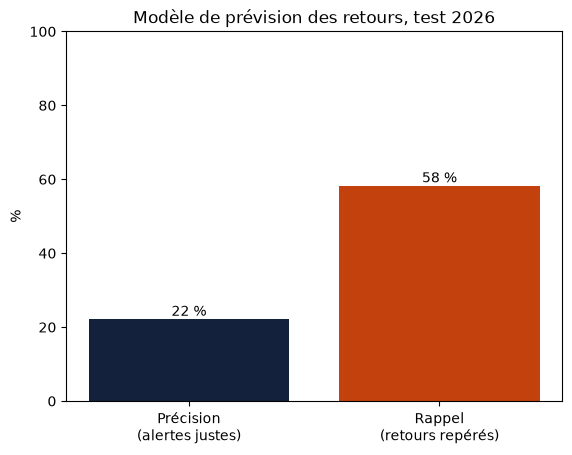

In [7]:
# Graphique : précision et rappel du modèle final sur 2026
import matplotlib.pyplot as plt

valeurs = [precision_score(y_test, y_pred), recall_score(y_test, y_pred)]
noms = ["Précision\n(alertes justes)", "Rappel\n(retours repérés)"]

plt.bar(noms, [v * 100 for v in valeurs], color=["#14213D", "#C2410C"])
for i, v in enumerate(valeurs):
    plt.text(i, v * 100 + 1, f"{v * 100:.0f} %", ha="center")   # on écrit le chiffre au-dessus de chaque barre
plt.ylabel("%")
plt.ylim(0, 100)
plt.title("Modèle de prévision des retours, test 2026")
plt.savefig("graphique_precision_rappel.png", dpi=150, bbox_inches="tight")   # image pour la présentation
plt.show()


### Réponses — Étape 5

Le test 2026 a été utilisé **une seule fois**, pour ce bloc. Modèle : régression logistique (C = 0,01). Résultats : précision **0,221** ; rappel **0,582** ; F1 **0,320** ; ROC-AUC **0,600** (Dummy : 0,5).

- **Faux positifs (FP = 427)** : on prédit « retour » mais le client garde le produit. Pour CycleNova : des actions inutiles (message, contrôle, frais) et peut-être un client gêné pour rien.
- **Faux négatifs (FN = 87)** : on prédit « pas de retour » mais le produit revient. Pour CycleNova : un retour non anticipé, avec son coût (remboursement, transport, stock).
- Le modèle retrouve un peu plus de la moitié des retours (121 sur 208, c'est le rappel). Mais sur 548 alertes (427 + 121), environ 4 sur 5 sont fausses (c'est la précision faible). La précision de 0,221 est à peine au-dessus de la part réelle de retours en 2026 (17,6 %).

## Étape 6 — Recommandation

Présentez le modèle retenu, sa performance hors échantillon, les risques de dérive dans le temps et les limites de la décision automatisée.

### Réponses — Étape 6

- **Modèle retenu** : régression logistique avec C = 0,01. Elle a le meilleur ROC-AUC en validation 2025 (0,590, contre 0,581 pour la Random Forest). Elle est aussi la plus simple à expliquer.
- **Performance hors échantillon** : ROC-AUC de **0,600** sur 2026, contre 0,5 pour le Dummy. C'est **à peine mieux que le hasard** : le modèle a un petit signal, mais il est faible. Les variables connues le jour de la vente expliquent peu les retours. La validation 2025 (0,590) et le test 2026 (0,600) sont proches : le modèle ne sur-apprend pas, mais il apprend peu.
- **Risques de dérive** : les produits, les prix, les promos et les clients changent avec le temps. Un modèle appris sur 2025 peut perdre en qualité. Il faut suivre ses scores chaque mois et le ré-entraîner.
- **Limites de la décision automatisée** : trop de faux positifs (427) pour bloquer ou pénaliser un client automatiquement. Le modèle ne connaît pas la **raison** des retours, et les données sont synthétiques. Je recommande de **ne pas automatiser** : s'en servir seulement comme aide (par exemple surveiller certaines catégories), avec une validation humaine, et chercher de meilleures variables (taille, description du produit, historique client) avant tout déploiement.